In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## attention-map

**Figure 1: Soft alignment found by RNNsearch-50 when translating an English sentence (columns) into French (rows).** Each cell is the attention weight α_ij the model gives to source word j when it generates target word i. The alignment is mostly monotonic along the diagonal, but the model aligns [zone] with [Area] (weight 0.71), jumping over [European] and [Economic], and then looks one word back at a time ([économique] → [Economic], 0.76; [européenne] → [European], 0.97).

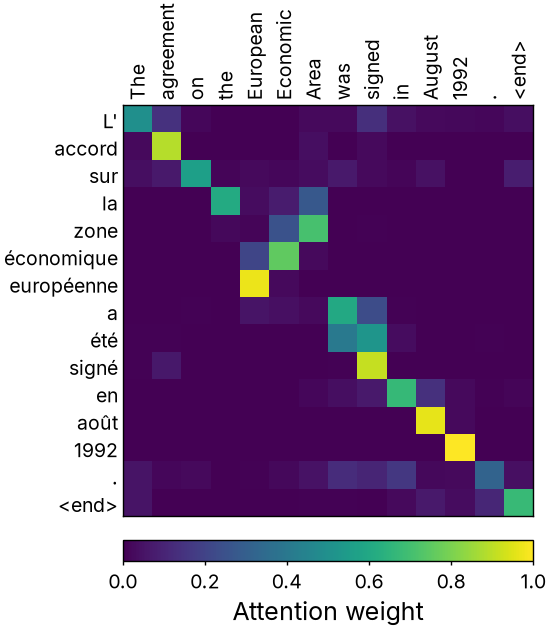

In [2]:
with open("../data/attention-map.json") as f:
    data = json.load(f)
weights = np.array(data["weights"])

fig, ax = plt.subplots(figsize=(2.75, 3))
im = ax.imshow(weights, aspect="auto", vmin=0, vmax=1)
ax.xaxis.tick_top()
ax.set_xticks(range(len(data["source_tokens"])), labels=data["source_tokens"], rotation=90, ha="center")
ax.set_yticks(range(len(data["target_tokens"])), labels=data["target_tokens"])
ax.tick_params(length=0)
ax.grid(False)
fig.colorbar(im, ax=ax, location="bottom", label="Attention weight")

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/attention-map.pdf")
fig.savefig("../outputs/attention-map.png")
plt.show()